# **Lab 7(B) - Mathematical and Statistical Filters**
**Course:** ARTI403 – Image Processing
**Student:** Mohammed Moayed Alquriniy – 2240007325

Noise models (Gaussian, Salt & Pepper, Exponential, Uniform) are added to a clean test image and then
removed with **mean filters** (arithmetic, geometric, harmonic, contra‑harmonic) and **order‑statistic filters**
(median, max, min, midpoint). Every filter is evaluated visually and with **PSNR** against the clean image.

In [2]:
pip install pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\moham\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import os
import cv2
import numpy as np
import pandas as pd

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)
np.random.seed(42)          # reproducible noise

IMG_DIR = 'images'
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)

def save(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=110, bbox_inches='tight')

def psnr(clean, test):
    return cv2.PSNR(clean, test)

## Adding noise to an image

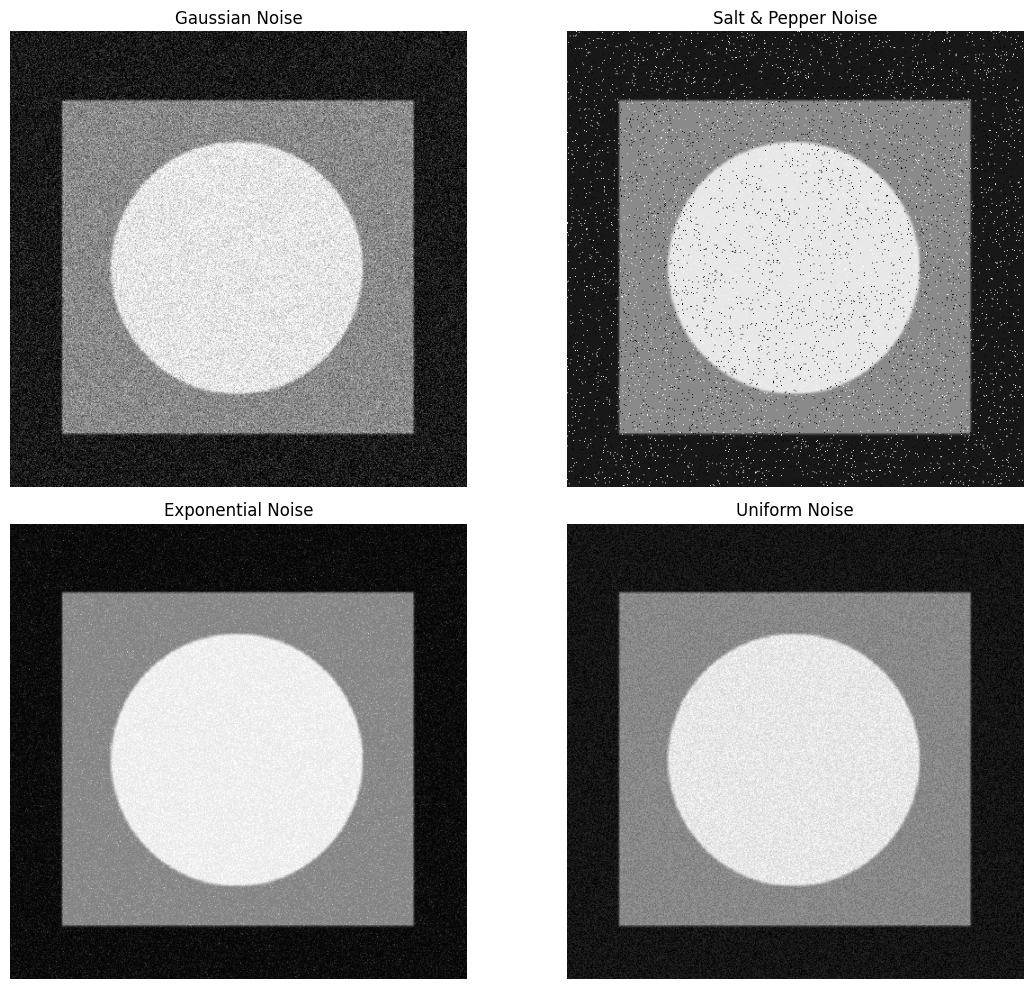

PSNR of noisy images vs clean:
  Gaussian      :  20.85 dB
  Salt & Pepper :  18.52 dB
  Exponential   :  25.69 dB
  Uniform       :  26.87 dB
  Salt only     :  17.73 dB
  Pepper only   :  19.30 dB


In [4]:
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
imgPath = os.path.join(IMG_DIR, 'noise.jpg')
img = cv2.imread(imgPath, 0)

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type in ("salt_pepper", "salt", "pepper"):
        amount = 0.04
        s_vs_p = {"salt_pepper": 0.5, "salt": 1.0, "pepper": 0.0}[noise_type]
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = int(np.ceil(amount * image.size * s_vs_p))
        coords = [np.random.randint(0, i - 1, num_salt) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = int(np.ceil(amount * image.size * (1.0 - s_vs_p)))
        coords = [np.random.randint(0, i - 1, num_pepper) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)


# 3. Generate Noisy Images
noise_gauss  = add_noise(img, "gaussian")
noise_sp     = add_noise(img, "salt_pepper")
noise_expo   = add_noise(img, "exponential")
noise_uni    = add_noise(img, "uniform")
noise_salt   = add_noise(img, "salt")      # salt only   (for contra-harmonic Q<0 and min filter)
noise_pepper = add_noise(img, "pepper")    # pepper only (for contra-harmonic Q>0 and max filter)

# 4. Display in 2x2 Grid
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B1_noise_models.png')
plt.show()

print('PSNR of noisy images vs clean:')
for n, im in [('Gaussian', noise_gauss), ('Salt & Pepper', noise_sp), ('Exponential', noise_expo),
              ('Uniform', noise_uni), ('Salt only', noise_salt), ('Pepper only', noise_pepper)]:
    print(f'  {n:14s}: {psnr(img, im):6.2f} dB')

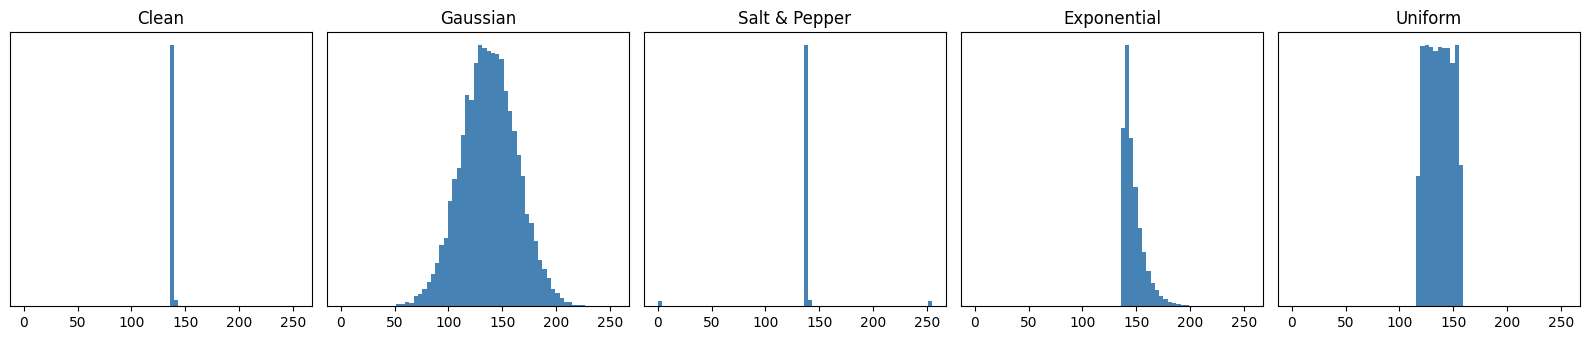

In [5]:
# Histograms show the shape of each noise model (taken from the flat grey region of the square)
patch = (slice(80, 120), slice(70, 430))   # flat grey band above the circle
plt.figure(figsize=(16, 3.5))
for i, (n, im) in enumerate([('Clean', img), ('Gaussian', noise_gauss), ('Salt & Pepper', noise_sp),
                             ('Exponential', noise_expo), ('Uniform', noise_uni)]):
    plt.subplot(1, 5, i + 1)
    plt.hist(im[patch].ravel(), bins=64, range=(0, 255), color='steelblue')
    plt.title(n); plt.yticks([])
plt.tight_layout(); save('B2_noise_histograms.png')
plt.show()

## **Arithmetic Mean Filter**
$$\hat f(x,y)=\frac{1}{mn}\sum_{(s,t)\in S_{xy}} g(s,t)$$

Both methods identical: True


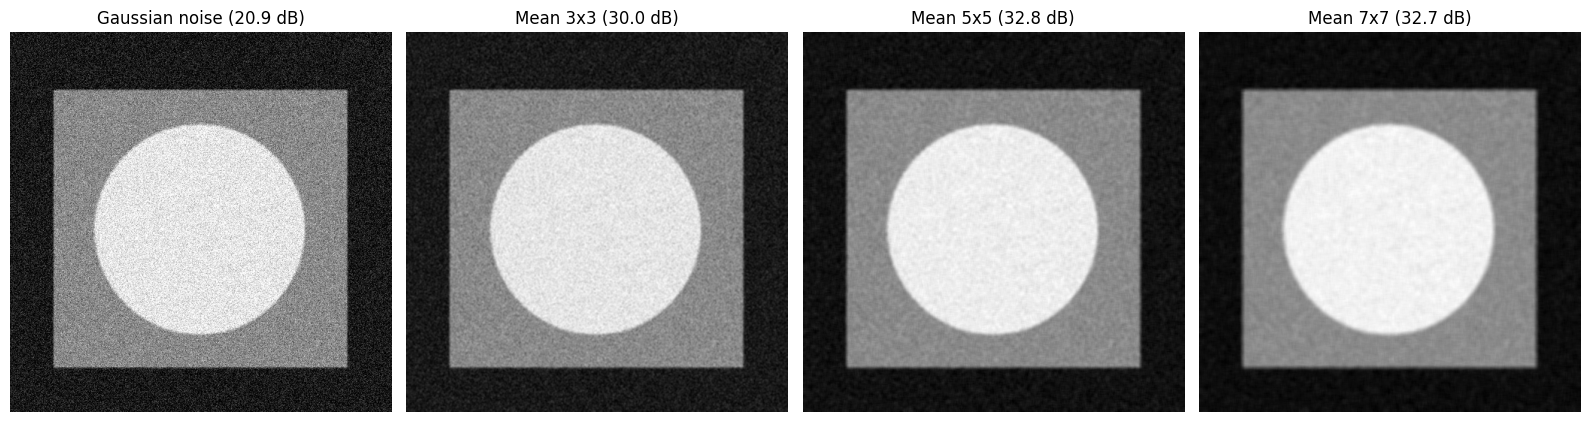

In [6]:
# --- METHOD 1: Using Built-in OpenCV function ---
# The larger the kernel, the smoother the image becomes (3x3, 5x5, 7x7 ...)
filtered_img = cv2.blur(noise_gauss, (3, 3))

# --- METHOD 2: Manual implementation using a Kernel ---
# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

print('Both methods identical:', np.array_equal(filtered_img, arithmetic_mean_manual))

blur5 = cv2.blur(noise_gauss, (5, 5))
blur7 = cv2.blur(noise_gauss, (7, 7))

plt.figure(figsize=(16, 4.5))
plt.subplot(141), plt.imshow(noise_gauss, cmap='gray'), plt.title(f'Gaussian noise ({psnr(img, noise_gauss):.1f} dB)')
plt.subplot(142), plt.imshow(filtered_img, cmap='gray'), plt.title(f'Mean 3x3 ({psnr(img, filtered_img):.1f} dB)')
plt.subplot(143), plt.imshow(blur5, cmap='gray'), plt.title(f'Mean 5x5 ({psnr(img, blur5):.1f} dB)')
plt.subplot(144), plt.imshow(blur7, cmap='gray'), plt.title(f'Mean 7x7 ({psnr(img, blur7):.1f} dB)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B3_arithmetic_mean.png')
plt.show()

## **Geometric Means**
$$\hat f(x,y)=\Big[\prod_{(s,t)\in S_{xy}} g(s,t)\Big]^{1/mn}$$

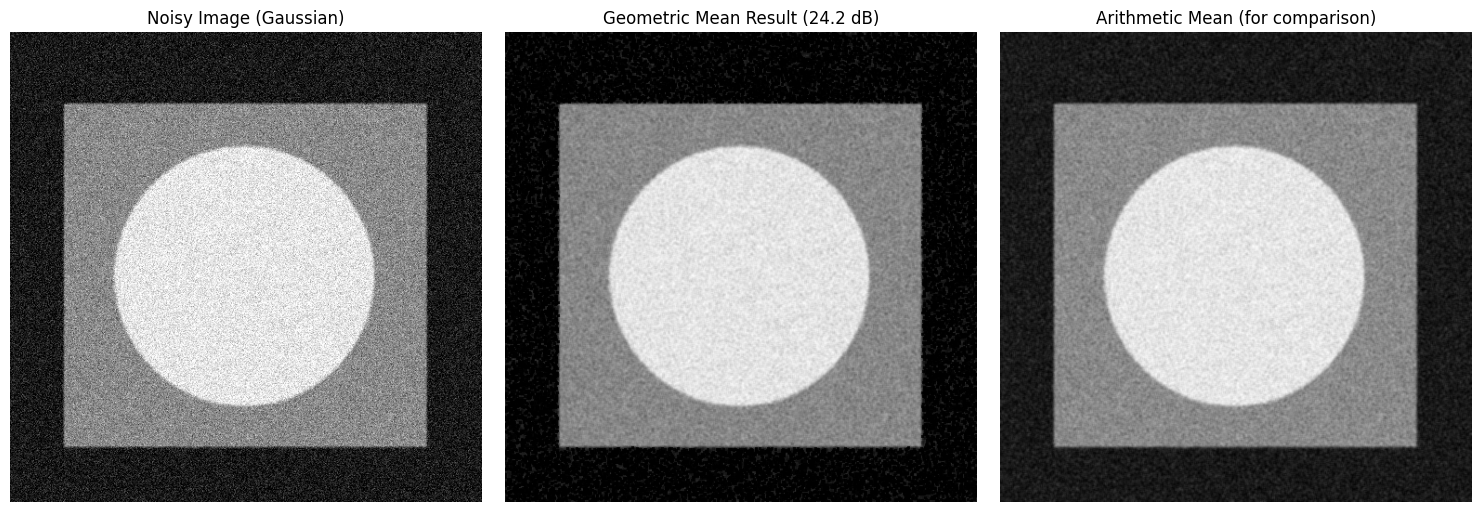

In [7]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6
    # 2. Apply the log-transform
    log_img = np.log(img_float)
    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)
    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)
    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)

noise_img = noise_gauss
result = geometric_mean_filter(noise_img, kernel_size=3)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image (Gaussian)')
plt.subplot(132), plt.imshow(result, cmap='gray'), plt.title(f'Geometric Mean Result ({psnr(img, result):.1f} dB)')
plt.subplot(133), plt.imshow(cv2.blur(noise_img, (3, 3)), cmap='gray'), plt.title('Arithmetic Mean (for comparison)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B4_geometric_mean.png')
plt.show()

## **Harmonic Means Filter**
$$\hat f(x,y)=\frac{mn}{\sum_{(s,t)\in S_{xy}} \frac{1}{g(s,t)}}$$
Works well for salt noise, fails for pepper noise (a single 0 makes the sum of reciprocals explode).

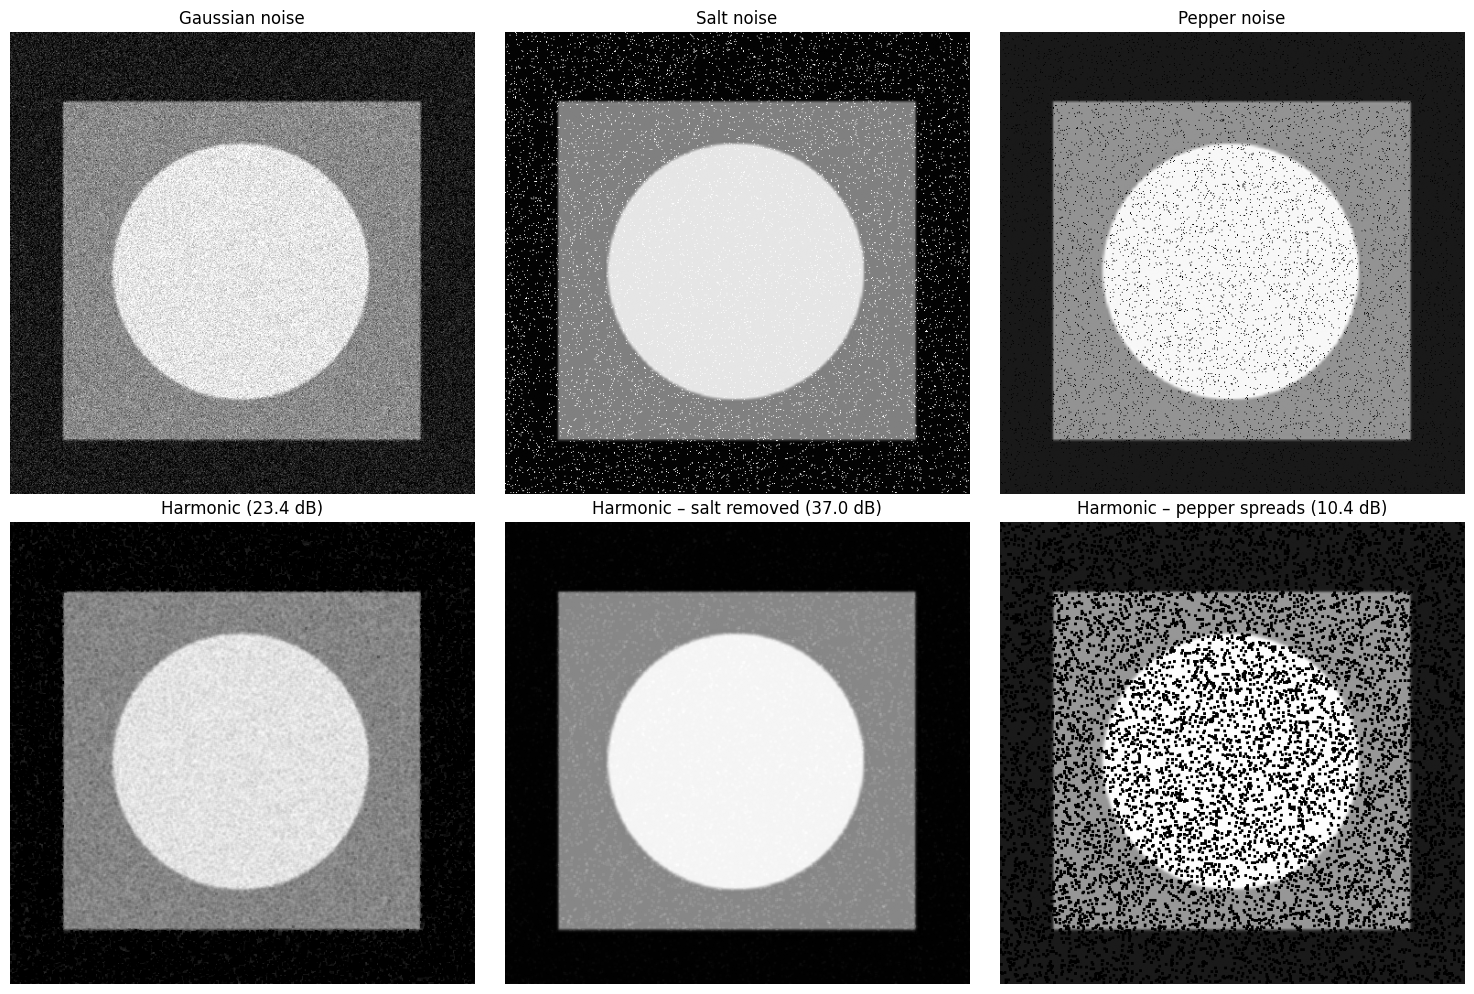

In [8]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64; tiny epsilon handles black pixels (0)
    img_float = image.astype(np.float64) + 1e-6
    # 2. Reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float
    # 3. Sum the reciprocals in a window
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)
    # 4. (Window Size) / Sum of Reciprocals
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal
    # 5. Clip and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)

h_gauss  = harmonic_mean_filter(noise_gauss)
h_salt   = harmonic_mean_filter(noise_salt)
h_pepper = harmonic_mean_filter(noise_pepper)

plt.figure(figsize=(15, 10))
plt.subplot(231), plt.imshow(noise_gauss, cmap='gray'),  plt.title('Gaussian noise')
plt.subplot(232), plt.imshow(noise_salt, cmap='gray'),   plt.title('Salt noise')
plt.subplot(233), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper noise')
plt.subplot(234), plt.imshow(h_gauss, cmap='gray'),  plt.title(f'Harmonic ({psnr(img, h_gauss):.1f} dB)')
plt.subplot(235), plt.imshow(h_salt, cmap='gray'),   plt.title(f'Harmonic – salt removed ({psnr(img, h_salt):.1f} dB)')
plt.subplot(236), plt.imshow(h_pepper, cmap='gray'), plt.title(f'Harmonic – pepper spreads ({psnr(img, h_pepper):.1f} dB)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B5_harmonic_mean.png')
plt.show()

## **Contra - Harmonic Mean Filter**
$$\hat f(x,y)=\frac{\sum g(s,t)^{Q+1}}{\sum g(s,t)^{Q}}$$
$Q>0$ removes **pepper**, $Q<0$ removes **salt**, $Q=0$ → arithmetic mean, $Q=-1$ → harmonic mean.

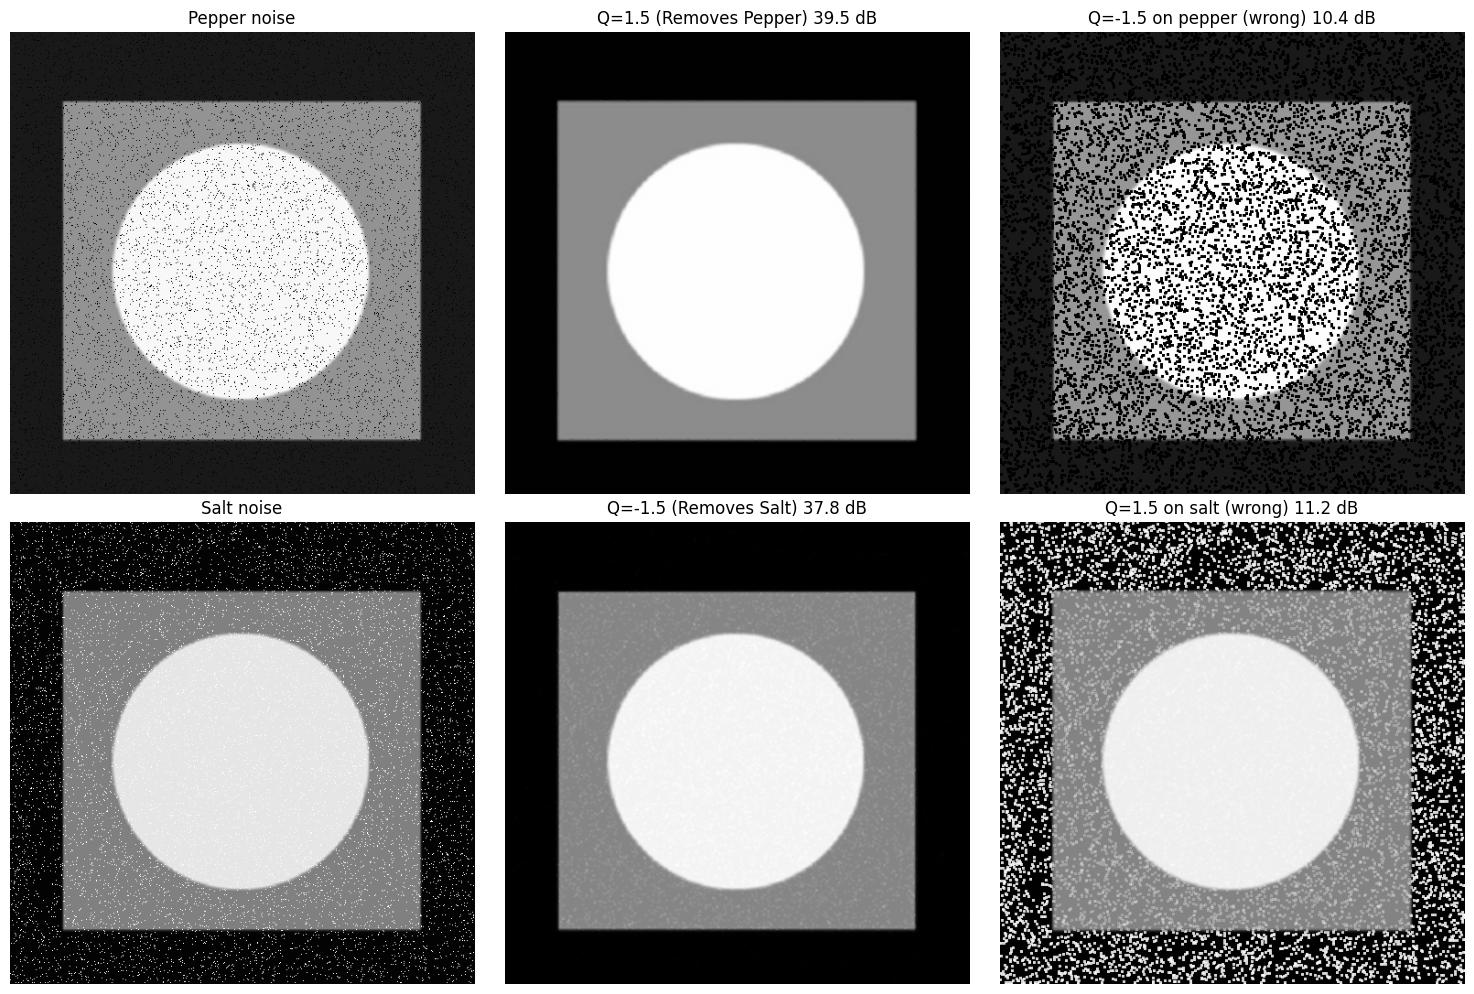

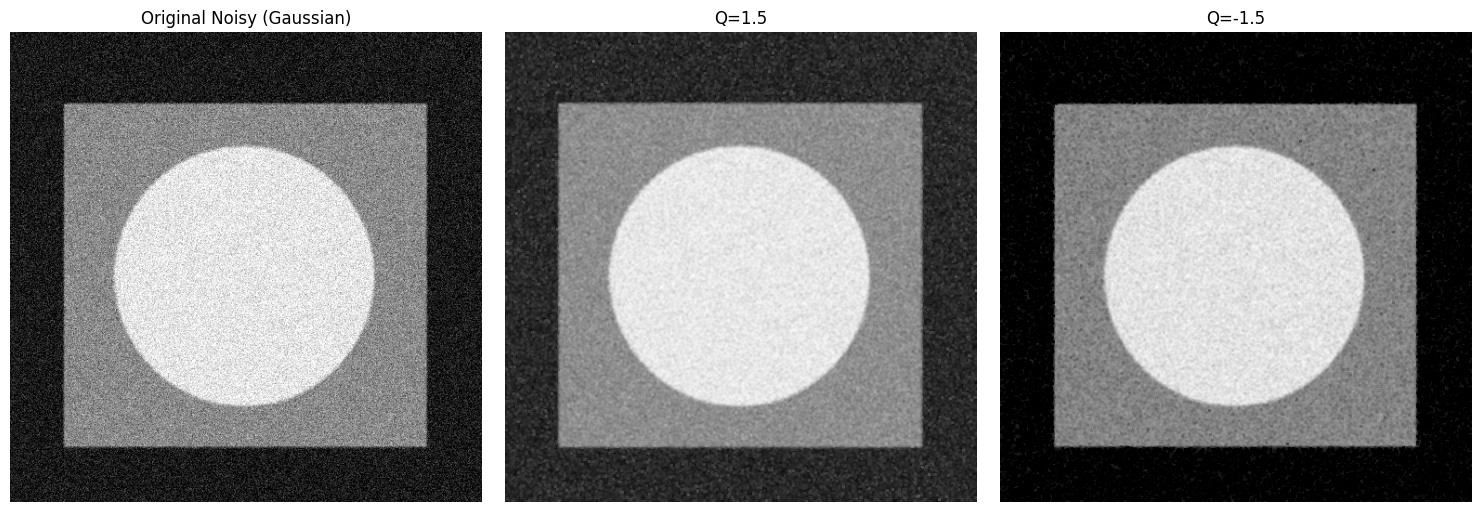

In [9]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    # 2. Numerator: Sum of pixels to the power (Q + 1)
    num_sum = cv2.filter2D(np.power(img_float, Q + 1), -1, kernel)
    # 3. Denominator: Sum of pixels to the power (Q)
    den_sum = cv2.filter2D(np.power(img_float, Q), -1, kernel)
    # 4. Divide (guard against division by zero)
    result = num_sum / (den_sum + 1e-6)
    return np.clip(result, 0, 255).astype(np.uint8)

# --- APPLICATIONS ---
# Q > 0 (1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_pepper, kernel_size=3, Q=1.5)
# Q < 0 (-1.5): Removes Salt Noise (white spots)
salt_removed   = contra_harmonic_mean(noise_salt,   kernel_size=3, Q=-1.5)
# Wrong sign of Q makes it worse
pepper_wrongQ  = contra_harmonic_mean(noise_pepper, kernel_size=3, Q=-1.5)
salt_wrongQ    = contra_harmonic_mean(noise_salt,   kernel_size=3, Q=1.5)

plt.figure(figsize=(15, 10))
plt.subplot(231), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper noise')
plt.subplot(232), plt.imshow(pepper_removed, cmap='gray'), plt.title(f'Q=1.5 (Removes Pepper) {psnr(img, pepper_removed):.1f} dB')
plt.subplot(233), plt.imshow(pepper_wrongQ, cmap='gray'), plt.title(f'Q=-1.5 on pepper (wrong) {psnr(img, pepper_wrongQ):.1f} dB')
plt.subplot(234), plt.imshow(noise_salt, cmap='gray'), plt.title('Salt noise')
plt.subplot(235), plt.imshow(salt_removed, cmap='gray'), plt.title(f'Q=-1.5 (Removes Salt) {psnr(img, salt_removed):.1f} dB')
plt.subplot(236), plt.imshow(salt_wrongQ, cmap='gray'), plt.title(f'Q=1.5 on salt (wrong) {psnr(img, salt_wrongQ):.1f} dB')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B6_contraharmonic.png')
plt.show()

# Effect of Q on the Gaussian-noise image (as in the original lab cell)
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_gauss, cmap='gray'), plt.title('Original Noisy (Gaussian)')
plt.subplot(132), plt.imshow(contra_harmonic_mean(noise_gauss, 3, 1.5), cmap='gray'), plt.title('Q=1.5')
plt.subplot(133), plt.imshow(contra_harmonic_mean(noise_gauss, 3, -1.5), cmap='gray'), plt.title('Q=-1.5')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Median Filter**
$$\hat f(x,y)=\operatorname{median}_{(s,t)\in S_{xy}}\{g(s,t)\}$$

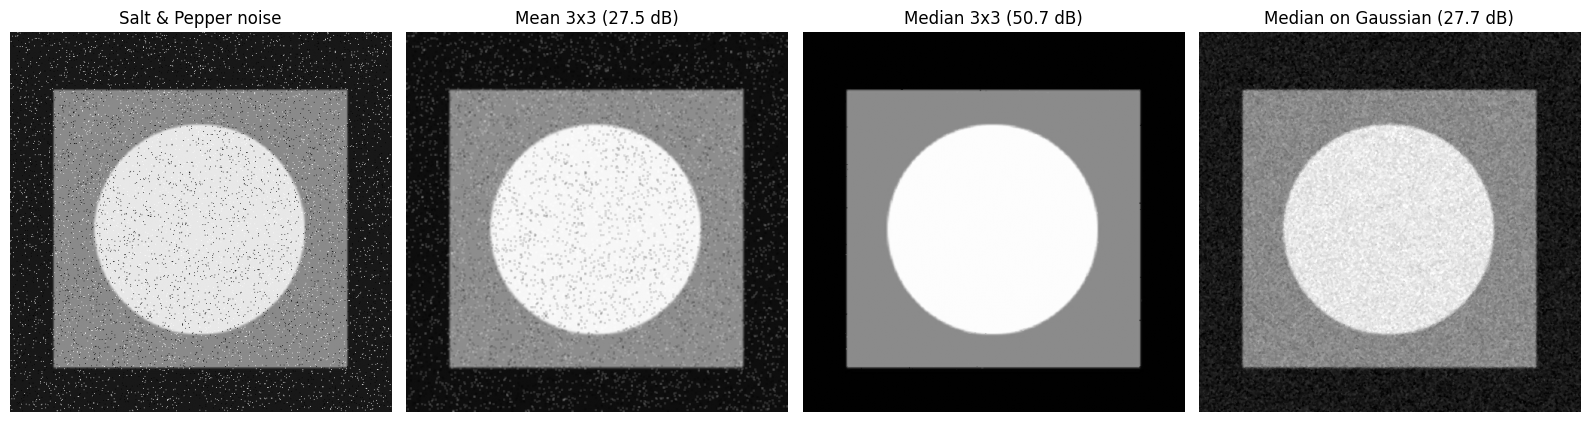

In [10]:
# The second argument is 'ksize' — it MUST be an odd integer (3, 5, 7, ...)
median_sp    = cv2.medianBlur(noise_sp, 3)
median_gauss = cv2.medianBlur(noise_gauss, 3)
mean_sp      = cv2.blur(noise_sp, (3, 3))

plt.figure(figsize=(16, 4.5))
plt.subplot(141), plt.imshow(noise_sp, cmap='gray'),     plt.title('Salt & Pepper noise')
plt.subplot(142), plt.imshow(mean_sp, cmap='gray'),      plt.title(f'Mean 3x3 ({psnr(img, mean_sp):.1f} dB)')
plt.subplot(143), plt.imshow(median_sp, cmap='gray'),    plt.title(f'Median 3x3 ({psnr(img, median_sp):.1f} dB)')
plt.subplot(144), plt.imshow(median_gauss, cmap='gray'), plt.title(f'Median on Gaussian ({psnr(img, median_gauss):.1f} dB)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B7_median.png')
plt.show()

## **Max and Min Filter**
Max (dilation) picks the brightest neighbour → removes **pepper**. Min (erosion) picks the darkest → removes **salt**.

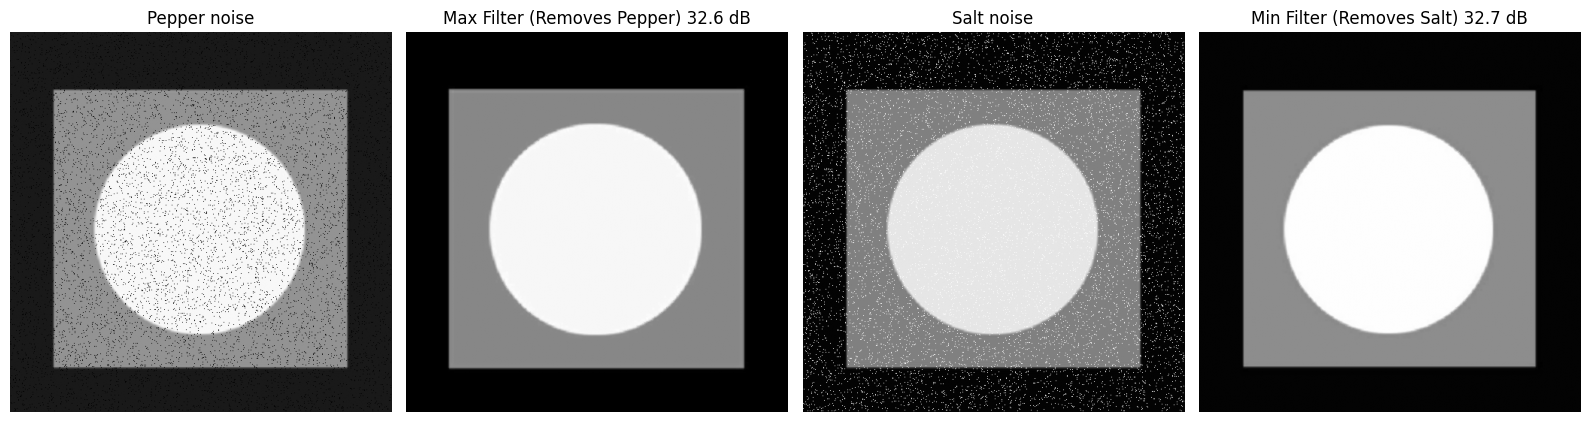

In [11]:
kernel = np.ones((3, 3), np.uint8)

max_filter = cv2.dilate(noise_pepper, kernel)   # Max filter on pepper noise
min_filter = cv2.erode(noise_salt, kernel)      # Min filter on salt noise

plt.figure(figsize=(16, 4.5))
plt.subplot(141), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper noise')
plt.subplot(142), plt.imshow(max_filter, cmap='gray'),   plt.title(f'Max Filter (Removes Pepper) {psnr(img, max_filter):.1f} dB')
plt.subplot(143), plt.imshow(noise_salt, cmap='gray'),   plt.title('Salt noise')
plt.subplot(144), plt.imshow(min_filter, cmap='gray'),   plt.title(f'Min Filter (Removes Salt) {psnr(img, min_filter):.1f} dB')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B8_max_min.png')
plt.show()

## **Mid-Point Filtering**
$$\hat f(x,y)=\tfrac12\big[\max g(s,t)+\min g(s,t)\big]$$ Best for randomly distributed noise such as Gaussian or uniform.

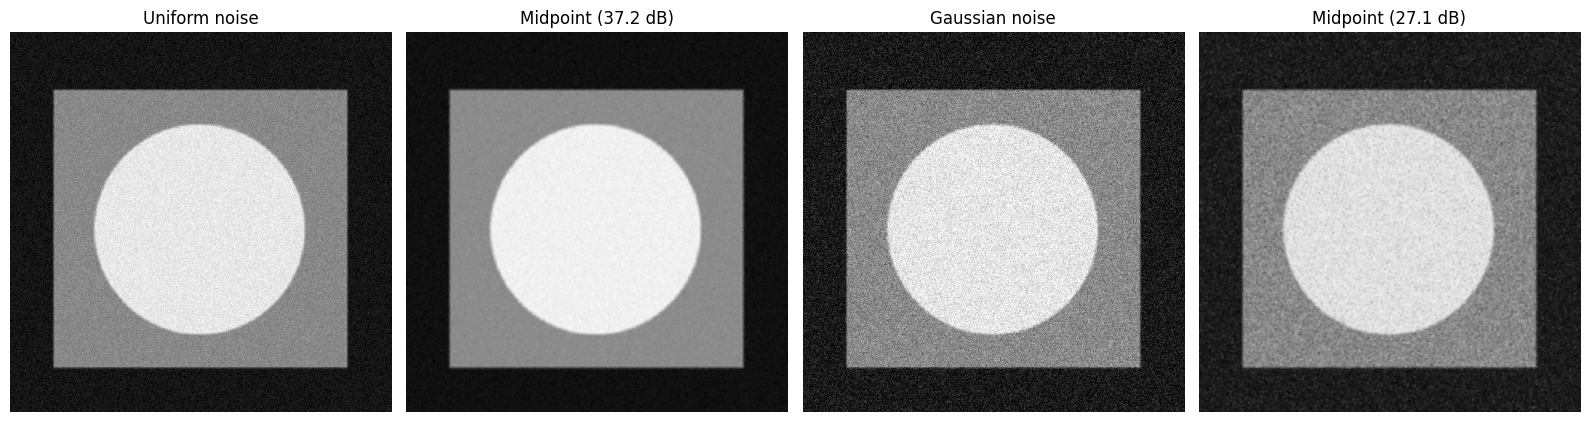

In [12]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    max_img = cv2.dilate(image, kernel).astype(np.float64)   # Maximum in neighbourhood
    min_img = cv2.erode(image, kernel).astype(np.float64)    # Minimum in neighbourhood
    midpoint = (max_img + min_img) / 2
    return midpoint.astype(np.uint8)

mid_uni   = midpoint_filter(noise_uni, 3)
mid_gauss = midpoint_filter(noise_gauss, 3)

plt.figure(figsize=(16, 4.5))
plt.subplot(141), plt.imshow(noise_uni, cmap='gray'),   plt.title('Uniform noise')
plt.subplot(142), plt.imshow(mid_uni, cmap='gray'),     plt.title(f'Midpoint ({psnr(img, mid_uni):.1f} dB)')
plt.subplot(143), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian noise')
plt.subplot(144), plt.imshow(mid_gauss, cmap='gray'),   plt.title(f'Midpoint ({psnr(img, mid_gauss):.1f} dB)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('B9_midpoint.png')
plt.show()

## **Quantitative comparison (PSNR in dB, 3×3 window)**
Higher is better. Every filter is applied to every noise type.

In [13]:
noises = {
    'Gaussian': noise_gauss, 'Uniform': noise_uni, 'Exponential': noise_expo,
    'Salt & Pepper': noise_sp, 'Salt': noise_salt, 'Pepper': noise_pepper,
}
filters = {
    'No filter':             lambda x: x,
    'Arithmetic mean':       lambda x: cv2.blur(x, (3, 3)),
    'Geometric mean':        lambda x: geometric_mean_filter(x, 3),
    'Harmonic mean':         lambda x: harmonic_mean_filter(x, 3),
    'Contra-harmonic Q=1.5': lambda x: contra_harmonic_mean(x, 3, 1.5),
    'Contra-harmonic Q=-1.5':lambda x: contra_harmonic_mean(x, 3, -1.5),
    'Median':                lambda x: cv2.medianBlur(x, 3),
    'Max':                   lambda x: cv2.dilate(x, np.ones((3, 3), np.uint8)),
    'Min':                   lambda x: cv2.erode(x, np.ones((3, 3), np.uint8)),
    'Midpoint':              lambda x: midpoint_filter(x, 3),
}

table = pd.DataFrame({n: {f: psnr(img, fn(im)) for f, fn in filters.items()} for n, im in noises.items()}).round(2)
table.to_csv(os.path.join(OUT_DIR, 'psnr_table.csv'))
print('Best filter per noise type:')
for col in table.columns:
    print(f'  {col:14s} -> {table[col].drop("No filter").idxmax():24s} ({table[col].drop("No filter").max():.2f} dB)')
table

Best filter per noise type:
  Gaussian       -> Arithmetic mean          (30.01 dB)
  Uniform        -> Midpoint                 (37.17 dB)
  Exponential    -> Min                      (33.44 dB)
  Salt & Pepper  -> Median                   (50.67 dB)
  Salt           -> Median                   (49.25 dB)
  Pepper         -> Median                   (47.40 dB)


,Gaussian,Uniform,Exponential,Salt & Pepper,Salt,Pepper
No filter,20.85,26.87,25.69,18.52,17.73,19.30
Arithmetic mean,30.01,35.81,28.21,27.52,25.95,27.52
Geometric mean,24.18,33.80,29.31,14.19,33.64,11.35
Harmonic mean,23.44,31.25,29.85,13.19,37.01,10.42
Contra-harmonic Q=1.5,23.28,32.35,26.17,14.04,11.25,39.51
Contra-harmonic Q=-1.5,23.01,29.32,30.32,13.19,37.79,10.42
Median,27.73,32.34,30.19,50.67,49.25,47.40
Max,16.64,23.36,18.77,11.56,8.84,32.64
Min,17.18,22.91,33.44,13.16,32.67,10.41
Midpoint,27.12,37.17,24.99,15.65,14.95,16.48


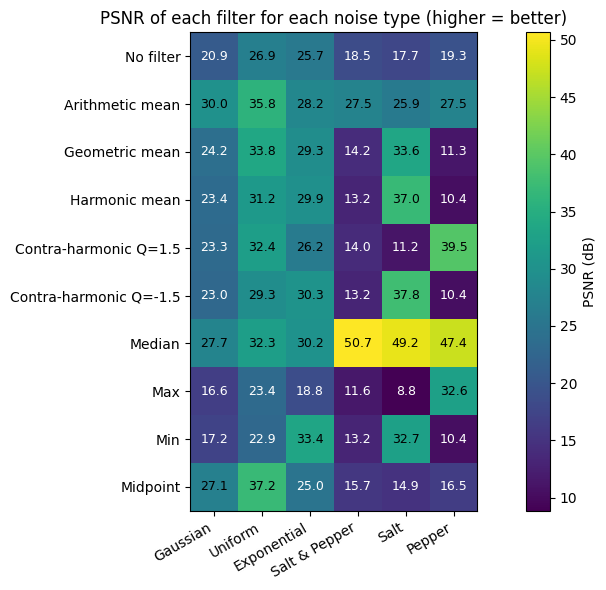

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(table.values, cmap='viridis')
ax.set_xticks(range(len(table.columns)), table.columns, rotation=30, ha='right')
ax.set_yticks(range(len(table.index)), table.index)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', color='white' if v < table.values.mean() else 'black', fontsize=9)
plt.colorbar(im, label='PSNR (dB)')
ax.set_title('PSNR of each filter for each noise type (higher = better)')
plt.tight_layout(); save('B10_psnr_heatmap.png')
plt.show()

## **Applying the filters to real noisy images**
The two provided images already contain impulse (salt & pepper) noise, so there is no clean reference; results are compared visually.

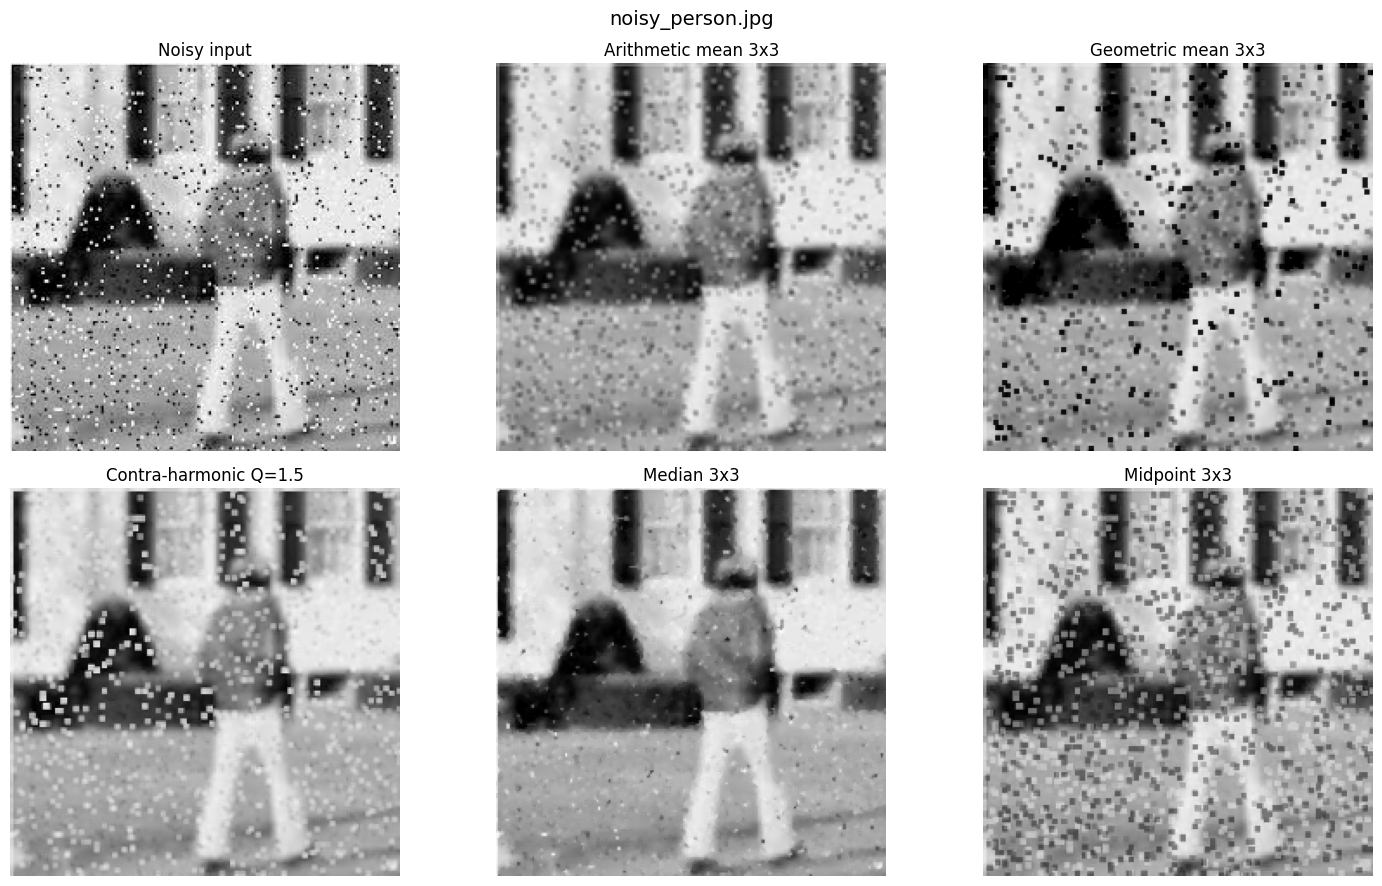

In [15]:
# ---- Person image: fine 1-pixel impulse noise -> 3x3 filters are enough ----
for fname, tag in [('noisy_person.jpg', 'B12')]:
    noisy = cv2.imread(os.path.join(IMG_DIR, fname), 0)
    k = 3
    outs = [
        ('Noisy input', noisy),
        (f'Arithmetic mean {k}x{k}', cv2.blur(noisy, (k, k))),
        (f'Geometric mean {k}x{k}', geometric_mean_filter(noisy, k)),
        (f'Contra-harmonic Q=1.5', contra_harmonic_mean(noisy, k, 1.5)),
        (f'Median {k}x{k}', cv2.medianBlur(noisy, k)),
        (f'Midpoint {k}x{k}', midpoint_filter(noisy, k)),
    ]
    plt.figure(figsize=(15, 9))
    for i, (t, im) in enumerate(outs):
        plt.subplot(2, 3, i + 1), plt.imshow(im, cmap='gray', vmin=0, vmax=255), plt.title(t), plt.axis('off')
    plt.suptitle(fname, fontsize=14)
    plt.tight_layout(); save(f'{tag}_{fname.split(".")[0]}.png')
    plt.show()

### Dome image – large noise blobs
In `noisy_dome.jpg` the noise was added *before* the image was enlarged, so every salt/pepper dot became a blurred
blob about 20 px wide. A median filter only removes an impulse when it covers **less than half** of the window, so
3×3 or 5×5 windows leave the dots untouched and only a very large window (31×31) removes them — at the cost of
blurring the dome.

A **selective (switching) median filter** fixes this: detect noise pixels as those far from a large‑window median,
then replace *only* those pixels and keep all other pixels unchanged.

Pixels detected as noise: 13.4%


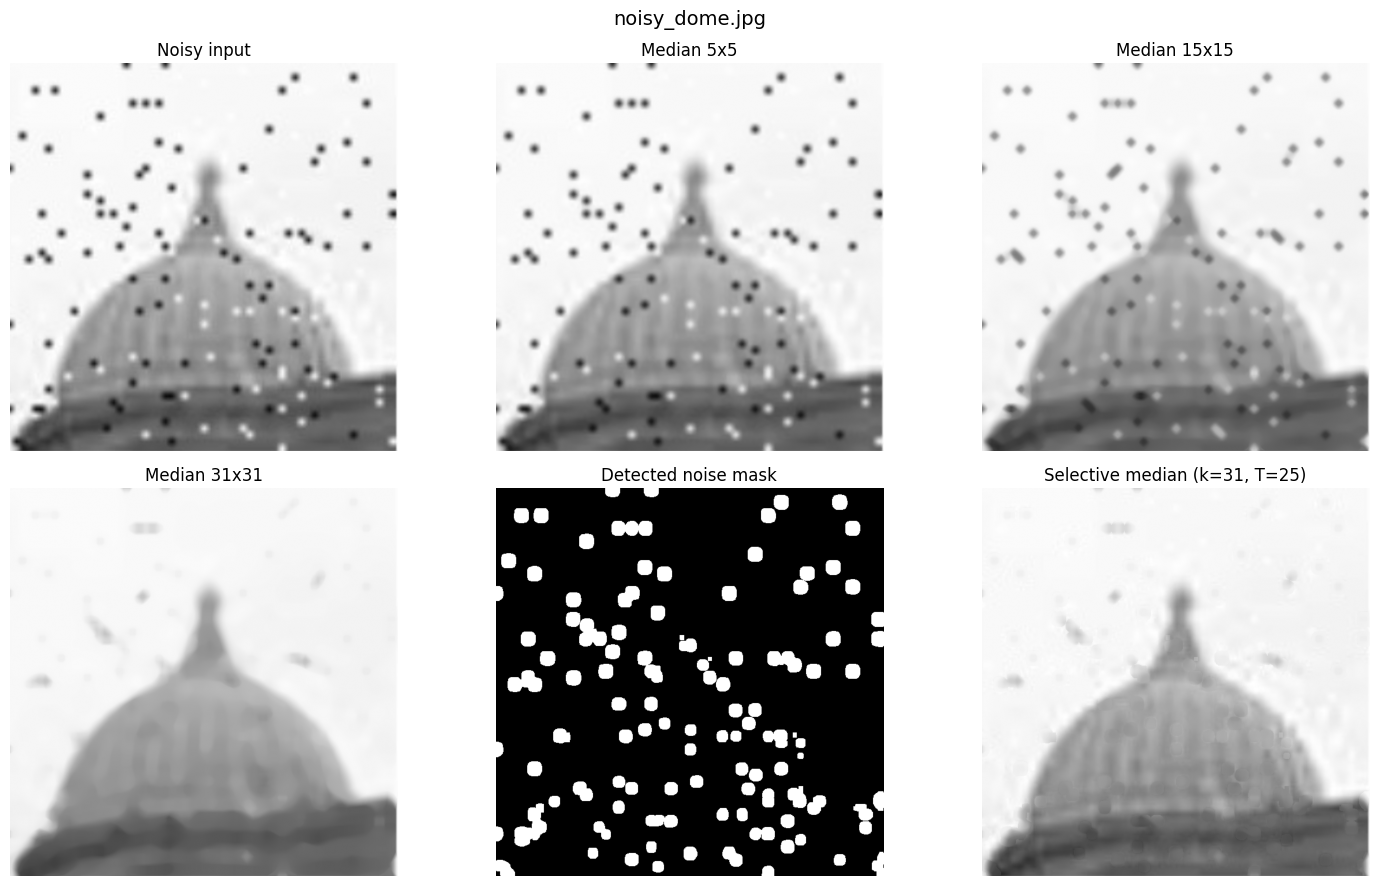

In [16]:
dome = cv2.imread(os.path.join(IMG_DIR, 'noisy_dome.jpg'), 0)

def selective_median(image, k=31, T=25, grow=7):
    background = cv2.medianBlur(image, k)                              # robust local estimate
    diff = np.abs(image.astype(np.int16) - background.astype(np.int16))
    mask = (diff > T).astype(np.uint8)                                 # 1 = noise pixel
    mask = cv2.dilate(mask, np.ones((grow, grow), np.uint8))           # cover blurred blob edges
    out = np.where(mask == 1, background, image).astype(np.uint8)
    return out, mask

dome_sel, dome_mask = selective_median(dome)
print(f'Pixels detected as noise: {dome_mask.mean() * 100:.1f}%')

outs = [
    ('Noisy input', dome),
    ('Median 5x5', cv2.medianBlur(dome, 5)),
    ('Median 15x15', cv2.medianBlur(dome, 15)),
    ('Median 31x31', cv2.medianBlur(dome, 31)),
    ('Detected noise mask', dome_mask * 255),
    ('Selective median (k=31, T=25)', dome_sel),
]
plt.figure(figsize=(15, 9))
for i, (t, im) in enumerate(outs):
    plt.subplot(2, 3, i + 1), plt.imshow(im, cmap='gray', vmin=0, vmax=255), plt.title(t), plt.axis('off')
plt.suptitle('noisy_dome.jpg', fontsize=14)
plt.tight_layout(); save('B11_noisy_dome.png')
plt.show()